# Descriptors and variability — what actually varies between films?

Every film's spectrum tells the same kind of story: strong absorption at short wavelengths, a fall to transparency as the material runs out of band gap, then a low, quiet floor.
What differs between films is the raw material of this project, the variation a generative model must learn to reproduce: how much each film absorbs, where its absorption switches off, how high the floor sits.

The [audit](audit.ipynb) established that the 517 films form one population whose variability is strikingly low-dimensional. This notebook compresses each curve into physically interpretable descriptors, attributes the leading variability directions to amplitude, edge and baseline motion, and asks the thickness-normalisation question directly: does working with the normalised curves `q = A/t` make descriptors more stable across film thickness than raw absorbance `A`, as Beer-Lambert predicts? and where does the prediction fail?

Terminology:
- The archive's "OD" is `q = A/t`, unit nm⁻¹ (with `t` in nm).
- Raw absorbance is recovered as `A = q·t` (dimensionless).
- Edge positions come from the storage grid with no smoothing.



In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from absynth.audit import SUBSTRATE_STACK_COLUMN
from absynth.explore import (
    pca_explained_variance,
    pca_scores,
    score_descriptor_correlations,
    thickness_stability,
)
from absynth.features import (
    baseline_level,
    edge_descriptors,
    window_integrals,
)
from absynth.loader import CurveSet, load_dataset
from absynth.preprocessing import (
    absorbance_from_q,
    require_complete,
    restrict_to_span,
)

DATA_DIR = Path("../data/raw/Dataset")

In [2]:
dataset = load_dataset(DATA_DIR)
curves = restrict_to_span(dataset.curves)  # 300–900 nm, all films complete
require_complete(curves)
thickness = dataset.thickness_nm
print(f"{curves.n_samples} films × {curves.n_wavelengths} wavelengths")

517 films × 301 wavelengths


## Descriptors

Five integrated-attenuation windows, the same spans that the archive ships as `ODint` columns, summarise *where* a film attenuates.
The baseline level is the mean `q` over 850–900 nm, chosen below the absorption edge. The MAPbI₃ edge sits near 775–800 nm in the literature. The choice is a stated convention, not a measurement from the dataset, and an elevated baseline may equally flag a red-shifted edge.
The two edge descriptors describe how each curve falls from strong absorption to transparency.
The reference level is the *plateau*: the typical curve height in the strong-absorption region (300–500 nm).
The *edge position* is the wavelength where the curve has fallen to half that level.
The *edge width* is how far, in nanometres, the curve travels while dropping from 90% to 10% of it. A sharp switch-off gives a small width, a gradual one a large width.
When a curve never reaches one of these levels inside the measured range, the descriptor is left empty rather than estimated; the counts are printed below.

In [3]:
descriptors_q = window_integrals(curves)
descriptors_q["q_baseline_850_900"] = baseline_level(curves)
edges = edge_descriptors(curves)
print(
    f"{edges['edge_50_nm'].isna().sum()} films without an edge "
    f"crossing inside the grid; "
    f"{edges['edge_width_10_90_nm'].isna().sum()} without a 10–90 width"
)
descriptors_q = descriptors_q.join(edges)
descriptors_q.describe().T

15 films without an edge crossing inside the grid; 308 without a 10–90 width


,count,mean,std,min,25%,50%,75%,max
q_int_300_900,517.0,2.977937,1.336714,0.238588,2.255498,2.765393,3.440139,12.244065
q_int_300_600,517.0,2.295898,1.103342,0.180458,1.701482,2.131055,2.758490,8.763349
q_int_400_700,517.0,1.746483,0.787461,0.038762,1.354636,1.651940,2.003567,7.506347
q_int_500_800,517.0,1.146605,0.508295,0.045767,0.890497,1.072928,1.294104,5.551160
q_int_600_900,517.0,0.682039,0.319835,0.058130,0.506379,0.624424,0.779342,3.480717
q_baseline_850_900,517.0,0.001103,0.000607,0.000252,0.000720,0.000984,0.001293,0.005779
edge_50_nm,502.0,630.374502,82.989762,508.000000,560.000000,616.000000,694.000000,890.000000
edge_width_10_90_nm,209.0,325.473684,40.129724,240.000000,290.000000,330.000000,356.000000,446.000000


Table: one row per descriptor, one column per distribution summary (count, mean, spread, quartiles, extremes).

Three things to notice.
- The five integrated windows decline steadily from the bluest to the reddest — films attenuate most at short wavelengths. The similar
relative spreads (each roughly half its mean) are why they later behave as a single amplitude axis.
- The sub-edge floor (`q_baseline_850_900`) sits near 0.001 nm⁻¹, typically 10–15% of a film's plateau — below the 10% level that the edge width needs, which is why only 209 of 517 films get a defined width.
- The edge position ranges over nearly 380 nm between films: the switch-off is a broad, variable shoulder rather than a single sharp wavelength, and the width (median 330 nm where defined) confirms that no film shows a textbook-sharp edge.

The width's coverage is itself a selection: only the low-floor films clear the 10% level, so the width statistics describe that 209-film subpopulation.

The first check validates the whole chain. Our trapezoidal integrals over the primary 300–900 nm window must reproduce the archive's own `ODint` column. Agreement to a small relative deviation means the loading, grid handling and orientation are all consistent with whatever produced the shipped numbers. A large deviation would mean a bug somewhere upstream, not physics.

In [4]:
shipped_odint = dataset.parameters["Perovskite_ODint_300_900_nm"]
relative_deviation = (
    descriptors_q["q_int_300_900"] - shipped_odint
).abs() / shipped_odint.abs()
relative_deviation.describe()

count    5.170000e+02
mean     1.022714e-03
std      7.591055e-04
min      9.949640e-07
25%      4.507967e-04
50%      9.300986e-04
75%      1.362599e-03
max      5.883142e-03
dtype: float64

## The same descriptors on raw absorbance

Beer-Lambert predicts `A ∝ t`, so every descriptor computed on `A` should carry the thickness factor that `q` removed.
We convert once with `absorbance_from_q` and run the same descriptor code on the result.
Linearity of the trapezoidal rule makes `∫A dλ = t · ∫q dλ` exactly, per film — a second, algebraic cross-check of the conversion.

In [5]:
curves_a = CurveSet(
    wavelengths_nm=curves.wavelengths_nm,
    sample_ids=curves.sample_ids,
    optical_density=absorbance_from_q(curves.optical_density, thickness),
)
descriptors_a = window_integrals(curves_a).rename(
    columns=lambda c: c.replace("q_int", "a_int")
)
descriptors_a["a_baseline_850_900"] = baseline_level(curves_a)

identity_gap = (
    descriptors_a["a_int_300_900"] - thickness * descriptors_q["q_int_300_900"]
).abs().max()
print(f"max |∫A dλ − t·∫q dλ| = {identity_gap:.3e}")

max |∫A dλ − t·∫q dλ| = 4.775e-12


## What the variability is made of

The PCA spectrum above says *how many* independent directions the curve cloud has. It cannot say what they are. PCA only finds the directions of largest spread. It knows nothing about absorption or edges. So we name the directions ourselves, with a plain question:

> When a film sits far along a direction, which descriptors move with it?

Mechanically, each component gives one score per film (517 numbers), and correlating those scores with a descriptor's 517 values measures how much the two move together. A correlation near ±1 means the axis and the descriptor track the same film-to-film variation, and the descriptor names the axis.

The table below runs that check for four components against all eight descriptors. One reading rule: each axis's sign is arbitrary (SVD output), so within a row only the pattern of signs matters. They would all flip together.

In [6]:
ratios = pca_explained_variance(curves.optical_density)
print("variance shares of the first four components:")
print(np.round(ratios[:4], 3))
scores = pca_scores(curves.optical_density, max_components=4)
score_descriptor_correlations(scores, descriptors_q).round(3)

variance shares of the first four components:
[0.874 0.088 0.021 0.008]


,q_int_300_900,q_int_300_600,q_int_400_700,q_int_500_800,q_int_600_900,q_baseline_850_900,edge_50_nm,edge_width_10_90_nm
component_1,0.981,0.999,0.952,0.802,0.654,0.511,-0.496,0.171
component_2,0.183,0.023,0.304,0.585,0.685,0.615,0.650,-0.469
component_3,-0.053,0.022,0.040,-0.113,-0.295,-0.456,-0.353,-0.592
component_4,0.017,-0.006,-0.011,0.027,0.090,0.152,0.069,0.186


- Component 1 is amplitude: it tracks the integrated windows almost perfectly (r = 0.98 with ∫q dλ over 300–900 nm, r = 0.999 over 300–600 nm) and carries 87% of the variance — with a UV tilt (the redder windows load it progressively less: 0.95, 0.80, 0.65) and some edge motion (r = -0.50).
- Component 2 (9% of variance) is red-side shape: it loads the red windows (0.59, 0.69), the baseline (0.62) and the edge position (0.65).
- Component 3 (2%) is descent steepness (width r = -0.59).

Amplitude dominates; shape is an order of magnitude smaller but structured, not noise.

## Thickness stability of `q` vs raw `A`

Beer-Lambert's central claim is proportionality: twice the film, twice the absorbance (`A ∝ t`).
If that held exactly, dividing by thickness would leave a pure material property, and the thickness factor would carry no information of its own.

The table below scores every descriptor two ways to test this:
- `cv`, the descriptor's spread across films relative to its mean,
- and `pearson_r`, how strongly it moves with measured thickness.

Under exact proportionality, raw-`A` descriptors would track thickness almost perfectly (`pearson_r` near 1) and carry the thickness factor in their spread, while `q`-descriptors would be thickness-blind (`pearson_r` near 0) and strictly more stable.

One caution for the `q` rows: part of any negative association is arithmetic — at fixed `A`, dividing by `t` builds in a downhill trend even with no physics involved. So the *direction* of the `q`-thickness association is read cautiously; its *magnitude* is the Beer-Lambert failure signal.

In [7]:
stability = pd.concat(
    {"q (normalised)": thickness_stability(descriptors_q, thickness),
     "A (raw)": thickness_stability(descriptors_a, thickness)}
)
stability.round(4)

cv  pearson_r
q (normalised) q_int_300_900        0.4489    -0.6686
               q_int_300_600        0.4806    -0.7043
               q_int_400_700        0.4509    -0.6105
               q_int_500_800        0.4433    -0.4639
               q_int_600_900        0.4689    -0.3646
               q_baseline_850_900   0.5504    -0.3353
               edge_50_nm           0.1317     0.5731
               edge_width_10_90_nm  0.1233    -0.4472
A (raw)        a_int_300_900        0.2434     0.5129
               a_int_300_600        0.2305     0.3166
               a_int_400_700        0.2893     0.5057
               a_int_500_800        0.3625     0.6438
               a_int_600_900        0.4215     0.6732
               a_baseline_850_900   0.5037     0.5203

The normalisation does not stabilise this population — the opposite. The q integrals spread more than the A integrals (cv 0.45 vs 0.24 for the primary window) and q anticorrelates with thickness strongly (r = -0.67), while raw A rises with thickness only weakly (r = +0.51). The two observations are two views of one fact: on average across this population, ∫A dλ grows with thickness more slowly than proportionally, so ∫A dλ per nanometre of film (which is what q measures) falls as films get thicker. That magnitude is the Beer-Lambert failure signal the check was built to expose. Whether it reflects dividing artefacts, genuine per-film sub-proportionality, or processing variables correlated with thickness cannot be separated from these curves alone. The practical conclusion for the modelling ahead: working on q does not remove thickness information, it re-encodes it as shape.

If Beer-Lambert held, the raw-`A` panel would ride a proportional trend with thickness and the `q` panel would show no tilt at all.
The scatter plots check that by eye:

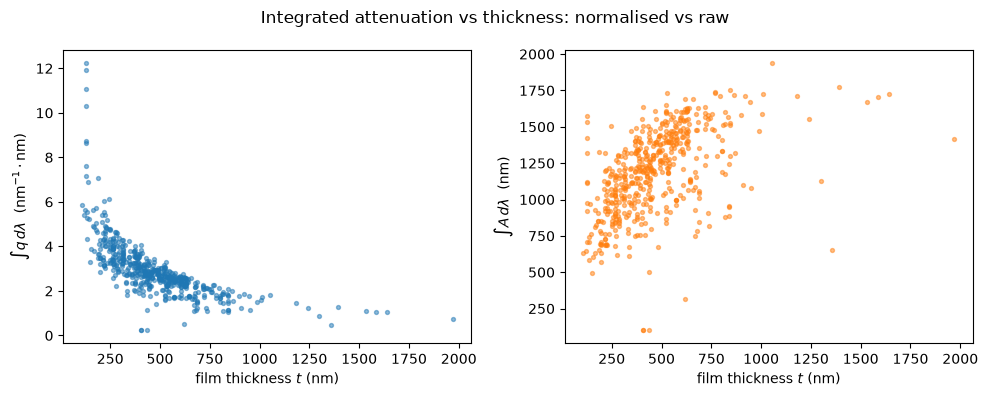

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
axes[0].scatter(thickness, descriptors_q["q_int_300_900"], s=8, alpha=0.5)
axes[0].set_ylabel(r"$\int q \, d\lambda$  (nm$^{-1}\cdot$nm)")
axes[1].scatter(thickness, descriptors_a["a_int_300_900"], s=8, alpha=0.5, color="tab:orange")
axes[1].set_ylabel(r"$\int A \, d\lambda$  (nm)")
for ax in axes:
    ax.set_xlabel("film thickness $t$ (nm)")
fig.suptitle("Integrated attenuation vs thickness: normalised vs raw")
fig.tight_layout()
plt.show()

Thickness is not the only thing films share. The substrate stack changes the optical path itself. A mesoporous TiO₂ layer scatters where plain glass does not.
So comparing films within a stack, where the fabrication is comparable, separates what the film does from where it sits.

The group medians differ strongly: the mesoporous-TiO₂ stack (n = 8) sits at 7.3 against 2.7–3.0 for the plain glass and corning stacks — scattering inflating apparent OD — while the
FTO/TiO₂-c group has only 5 films.

Descriptive only: the small stacks support no stratified modelling claim, but group membership must travel with the data for held-out-group evaluation and conditioning.

In [9]:
by_stack = descriptors_q[["q_int_300_900"]].join(
    dataset.parameters[SUBSTRATE_STACK_COLUMN]
)
by_stack.groupby(SUBSTRATE_STACK_COLUMN)["q_int_300_900"].agg(
    ["count", "median"]
).round(4)

,count,median
Substrate_stack_sequence,,
FTO / TiO2-c,5,1.4923
corning,191,3.0354
glass,313,2.6690
glass / TiO2-c / TiO2-mp,8,7.2832


## Findings

1. **Variability is amplitude-dominated.** One component carries 87% of the population's variance and is almost perfectly tracked by the integrated windows; red-side shape contributes at the ~9% level and descent steepness at ~2%. A compact linear model remains the baseline to beat.
2. **The processing chain checks out.** Our trapezoidal integrals reproduce the archive's ODint columns to ≤ 0.6% relative deviation (median 0.09%), and the absorbance conversion satisfies ∫A dλ = t·∫q dλ to machine precision.
3. **Beer-Lambert proportionality fails measurably.** q anticorrelates with thickness (r = -0.67) and is *less* stable across thickness than raw A (cv 0.45 vs 0.24); on average, ∫A dλ grows with thickness more slowly than proportionally. Part of the q-t anticorrelation may be arithmetic, but the magnitude is a genuine failure signal: normalised curves still carry thickness information, re-encoded as shape.
4. **The descents are broad, not textbook edges.** The median half-plateau crossing sits at 616 nm (range 508–890) — on a long shoulder, well short of the ~775–800 nm MAPbI₃ literature value; the median curve's steep final drop near 760–780 nm lies at only ~20% of its plateau. Only 209 of 517 curves fall below 10% of their plateau inside the grid (width undefined for the rest; median width 330 nm where defined), and 15 never cross 50%. Edge descriptors are grid-quantised shape summaries, not band-gap claims.
5. **Substrate stack moves the baseline.** Group medians of ∫q dλ span 1.5–7.3 across stacks (mesoporous TiO₂ scatters); the small stacks (n = 5 and 8) support description, not stratified claims — group membership travels with the data for later held-out-group evaluation.
